## Introduction

glassnode에서 제공되는 일별 온체인 데이터와  
비트코인 수익률간의 lead-lag relationship을 찾아본다.  

## Import Module

In [1]:
import os
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from util import research as rs

## Load Data

In [2]:
def agg_json(data_dir ='glassnode', is_btc=True):
    """aggregate json files to dataframe."""
    
    btc_glass_node = os.listdir(data_dir)
    eth_glass_node = []

    ## file path split - BTC / ETH
    for i, file in enumerate(btc_glass_node):
        if file.find("ETH") != -1:
            eth_glass_node.append(btc_glass_node.pop(i))

    def get_df(path):
        names = path.split('\\')[-1].split('_')[:-1]
        name = "_".join(names)
        with open(path, "r") as f: 
            json_data = json.loads(json.load(f))
            df = pd.DataFrame(json_data)
            df.columns = ['time', name]
            return df.set_index('time')

    glass_node = btc_glass_node if is_btc else eth_glass_node
    glass_path = [os.path.join(data_dir, path) for path in glass_node]
    df = pd.concat(map(get_df, glass_path), axis=1)
    return df


def agg_df(is_btc=True):
    """aggregate on-chain data and close data"""
    onchain_df = agg_json(is_btc=is_btc)
    onchain_df.index = pd.to_datetime(onchain_df.index, unit="s")

    ticker = "BTC" if is_btc else "ETH"
    close_df = pd.read_csv(f"binance_1m_{ticker}USDT.csv")
    close_df = close_df[['timestamp', 'close']].set_index('timestamp').copy()
    close_df.index = pd.to_datetime(close_df.index, unit="ms")

    close_df = close_df.resample('1d').last()
    final_df = close_df.merge(onchain_df, how='left', left_index=True, right_index=True)
    return final_df

btc_df = agg_df(is_btc=True)
eth_df = agg_df(is_btc=False)

"""Remove pi_cycle_top because it's not on-chain data."""
btc_df['pi_cycle_top'] # is indicating ma111 of close and ma350 times 2. So it has dictionary values, drop it 
btc_df.drop('pi_cycle_top', axis=1, inplace=True)

eth_df['pi_cycle_top'] # is indicating ma111 of close and ma350 times 2. So it has dictionary values, drop it 
eth_df.drop('pi_cycle_top', axis=1, inplace=True)

## Analysis

시계열 데이터의 정상성 확보를 위해  
로그변환 및 차분을 실행한다.
이미 ratio의 값이 경우 차분만 실행한다.  

또한 음수의 값을 가지는 'price_drawdown_relative'의 경우 (-1)을 곱해 양수로 이용한다.  

강건성을 위해, train/test 셋을 나누어 진행 

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [7]:
eth_temp = eth_df.copy()

rel_change_col = ["price_drawdown_relative",]
pct_change_col = ["rate", "staking_phase_0_goal_percent",]
nominal_col = eth_temp.columns[~eth_temp.columns.isin(rel_change_col + pct_change_col)]

eth_temp['price_drawdown_relative'] = eth_temp['price_drawdown_relative'] * (-1)
eth_temp[rel_change_col] = eth_temp[rel_change_col].diff(1)
eth_temp[pct_change_col] = (eth_temp[pct_change_col]/100).diff(1)

eth_temp[nominal_col] = np.log(eth_temp[nominal_col]/eth_temp[nominal_col].shift(1))
full_eth = eth_temp.loc[:, ~eth_temp.iloc[1:].isna().any(axis=0)].copy()
full_eth = full_eth.iloc[1:]

btc_temp = btc_df.copy()
btc_temp = btc_temp.astype(float)

rel_change_col = ["price_drawdown_relative",]
pct_change_col = ["rate",]
nominal_col = btc_temp.columns[~btc_temp.columns.isin(rel_change_col + pct_change_col)]
nominal_col = btc_temp.columns

btc_temp['price_drawdown_relative'] = btc_temp['price_drawdown_relative'] * (-1)
btc_temp[rel_change_col] = btc_temp[rel_change_col].diff(1)
btc_temp[pct_change_col] = (btc_temp[pct_change_col]/100).diff(1)

btc_temp[nominal_col] = np.log(btc_temp[nominal_col]/btc_temp[nominal_col].shift(1))
full_btc = btc_temp.loc[:, ~btc_temp.iloc[1:].isna().any(axis=0)].copy()
full_btc = full_btc.iloc[1:]

In [8]:
full_eth

,close,active_count,block_count,block_height,block_interval_mean,block_interval_median,block_size_mean,block_size_sum,count,current,...,receiving_count,sending_count,sopr,transfers_count,transfers_volume_mean,transfers_volume_median,transfers_volume_sum,volume_mean,volume_median,volume_sum
timestamp,,,,,,,,,,,,,,,,,,,,,
2020-01-02,-0.027758,0.100520,0.131345,0.000617,-0.131496,-0.087011,-0.020073,0.111272,0.070320,0.000109,...,0.092522,0.142138,0.020129,0.090779,0.503669,0.175260,0.594448,-0.115263,-0.096562,-0.034754
2020-01-03,0.054766,0.180473,0.138406,0.000708,-0.138290,-0.200671,-0.037647,0.100759,0.156603,0.000125,...,0.227545,0.213150,-0.000361,0.212768,0.293121,0.111082,0.505889,0.024669,0.016152,0.164700
2020-01-04,-0.001117,-0.053379,0.007333,0.000713,-0.007472,0.000000,-0.019024,-0.011691,-0.039029,0.000126,...,-0.080382,0.026804,0.016488,0.030948,-0.522940,-0.591768,-0.491993,-0.175049,-0.258936,-0.214621
2020-01-05,0.008681,-0.052728,-0.012560,0.000704,0.012525,0.000000,-0.033132,-0.045691,-0.067901,0.000124,...,-0.059560,-0.138969,0.001827,-0.141365,-0.089272,0.231445,-0.230637,0.033329,0.002649,-0.030195
2020-01-06,0.062843,0.156281,0.014992,0.000714,-0.014749,0.000000,0.097409,0.112401,0.181630,0.000126,...,0.139216,0.165680,0.003909,0.124629,0.477317,0.236500,0.601947,0.133384,0.272340,0.310814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-09-27,0.023344,0.129342,0.000418,0.000344,-0.000418,0.000000,0.003580,0.003998,0.054666,0.000005,...,0.088091,0.091161,0.006098,0.036659,0.155174,-0.105361,0.191833,-0.352154,-0.371618,-0.308478
2024-09-28,-0.007159,-0.022631,-0.000976,0.000344,0.000976,0.000000,0.025421,0.024445,-0.069548,0.000011,...,-0.112158,-0.076342,0.004740,-0.116683,-0.857847,-0.289165,-0.974530,-0.561993,-0.562110,-0.638711
2024-09-29,-0.006597,-0.029495,0.000140,0.000344,-0.000140,0.000000,0.004355,0.004495,-0.005411,0.000011,...,-0.002122,0.037501,-0.002795,0.045909,-0.112355,0.035915,-0.066446,0.086056,0.096938,0.088636


In [9]:
def split_train_test(df, train_ratio=0.7):
    if len(df) < 10:
        raise ValueError("Too small dataframe (<10)")
    
    train_max = round(len(df) * train_ratio)
    return df.iloc[:train_max, :], df.iloc[train_max:, :]

train_btc, test_btc = split_train_test(full_btc)
train_eth, test_eth = split_train_test(full_eth)

### Using Granger Causality

In [10]:
from statsmodels.tsa.stattools import grangercausalitytests

def test_granger(df, maxlag=10):
    for col in df.columns:
        pval_list = []
        if col == 'close':
            continue
        
        result = grangercausalitytests(df[['close', col]], maxlag=maxlag, verbose=False)
        for lag in range(1, maxlag+1):
            pval = result[lag][0]['params_ftest'][1]
            pval_list.append(pval)
            
            if pval < 0.01:
                print(f"{col} : lag {lag} is statistically significant.")
         
space = 30
MAXLAG = 15

print("-"*space + "BTC" + "-"*space)       
test_granger(train_btc, MAXLAG)
print("-"*space + "ETH" + "-"*space)
test_granger(train_eth, MAXLAG)

------------------------------BTC------------------------------
------------------------------ETH------------------------------
block_count : lag 11 is statistically significant.
block_count : lag 12 is statistically significant.
block_count : lag 13 is statistically significant.
block_count : lag 14 is statistically significant.
block_height : lag 7 is statistically significant.
block_height : lag 8 is statistically significant.
block_height : lag 9 is statistically significant.
block_height : lag 10 is statistically significant.
block_height : lag 11 is statistically significant.
block_height : lag 12 is statistically significant.
block_height : lag 13 is statistically significant.
block_height : lag 14 is statistically significant.
block_height : lag 15 is statistically significant.


### Using VAR Model

In [43]:
class Printer:
    """
    print left and right beutifully.
    Unfortunally, it works only for numbers and english. not korean..
    """
    
    def __init__(self, split=2, space=50, fill_space=" "):
        self.count = 0
        self.last_length = 0
        self.space = space
        self.fill_space = fill_space
        self.split=split
        
    def print(self, text, oneline=False):
        if oneline:
            print(text)
            return
            
        if self.count == 0:
            if len(text) > self.space:
                raise ValueError(f"Exceed space. Try new Printer with large space over {len(text)}")
            print(text, end="")
            self.count += 1
            self.last_length = len(text)
        
        else:
            margin = self.space - self.last_length
            print(self.fill_space * margin, end="| ")
            print(text, end="")
            self.last_length = len(text)
            self.count += 1
            if self.count == self.split:
                self.count = 0
                print("")
            

In [47]:
print(3)

3


In [59]:
from statsmodels.tsa.api import VAR

def test_var(df, maxlag=10):
    printer = Printer(split=4, space=20)
    var_results = []
    for col in df.columns:
        if col == "close":
            continue
        
        min_aic = np.inf
        min_model = None
        min_lag = 0
        for lag in range(1, 10+1):
            # VAR 모델 피팅
            model = VAR(df[['close', col]])
            fitted_model = model.fit(maxlags=lag)
            if fitted_model.aic < min_aic:
                min_lag = lag
                min_aic = fitted_model.aic
                min_model = fitted_model
                
        if min_model is not None:
            for i in range(2, len(min_model.pvalues), 2):    
                
                if min_model.pvalues['close'].iloc[i].min() < 0.01:
                    printer.print(f"{col}")
                    printer.print(f"VAR LAG: {min_lag}")
                    printer.print(f"significant lag: {i//2}")
                    printer.print(f"coef: {min_model.coefs[i//2-1][0][1]:.3f}")
                    
            var_results.append(min_model)
    
    return var_results

space = 40
MAXLAG = 20

print("-"*space + "BTC" + "-"*space)       
var_btc = test_var(train_btc, MAXLAG)
print("-"*space + "ETH" + "-"*space)
var_eth = test_var(train_eth, MAXLAG)

----------------------------------------BTC----------------------------------------
active_count        | VAR LAG: 8          | significant lag: 7  | coef: 0.046
sending_count       | VAR LAG: 8          | significant lag: 7  | coef: 0.031
utxo_spent_count    | VAR LAG: 8          | significant lag: 7  | coef: 0.028
----------------------------------------ETH----------------------------------------
block_height        | VAR LAG: 7          | significant lag: 7  | coef: 338.587
sopr                | VAR LAG: 10         | significant lag: 2  | coef: -0.130
sopr                | VAR LAG: 10         | significant lag: 3  | coef: -0.142


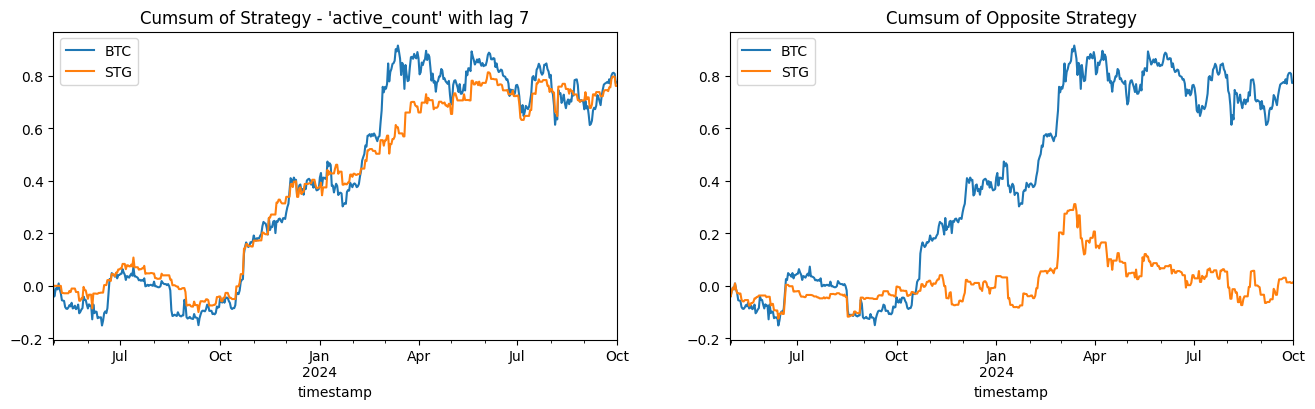

Entire Trading days : 521
Trading days for left: 248                                                                | Trading days for right: 273
Average Return for left: 0.0031                                                           | Average Return for right: 0.0001
Cummulative Sum Return for left: 0.7621                                                   | Cummulative Sum Return for right: 0.0142


In [68]:
# Test profitability 
def test_profitability(df, lag_col="active_count", lag=7, cost=0.0015):
    printer = Printer(2, 90)
    width, height = 16, 4
    fig, ax = plt.subplots(1, 2, figsize=(width, height))
    flag = df[lag_col].shift(lag) > 0 # t-lag 일 전의 on-chain 데이터가 양수였을 경우, t-1 시점에 종가로 매수했다고 가정.
    
    ## benchmark.
    df['close'].cumsum().plot(ax=ax[0])
    df['close'].cumsum().plot(ax=ax[1])
    
    ## Strategy
    cumrtn_stg = df['close'].mask(~flag).fillna(0).cumsum()
    cumrtn_opp = df['close'].mask(flag).fillna(0).cumsum()
    
    cumrtn_stg.plot(ax=ax[0])
    cumrtn_opp.plot(ax=ax[1])
    
    ax[0].legend(["BTC", "STG"])
    ax[1].legend(["BTC", "STG"])
    
    ax[0].set_title(f"Cumsum of Strategy - '{lag_col}' with lag {lag}")
    ax[1].set_title("Cumsum of Opposite Strategy")
    plt.show()
    
    printer.print(f"Entire Trading days : {len(df)}", oneline=True)
    printer.print(f"Trading days for left: {flag.sum()}")
    printer.print(f"Trading days for right: {(~flag).sum()}")
    
    printer.print(f"Average Return for left: {df['close'][flag].mean():.4f}")
    printer.print(f"Average Return for right: {df['close'][~flag].mean():.4f}")
    
    printer.print(f"Cummulative Sum Return for left: {cumrtn_stg.iloc[-1]:.4f}")
    printer.print(f"Cummulative Sum Return for right: {cumrtn_opp.iloc[-1]:.4f}")
    
    # printer.print(f"Sharpe Ratio for left: {df['close'][flag].mean() /  df['close'][flag].std():.4f}")
    # printer.print(f"Sharpe Ratio for right: {df['close'][~flag].mean() /  df['close'][~flag].std():.4f}")
    
test_profitability(test_btc, 'active_count', lag=7)

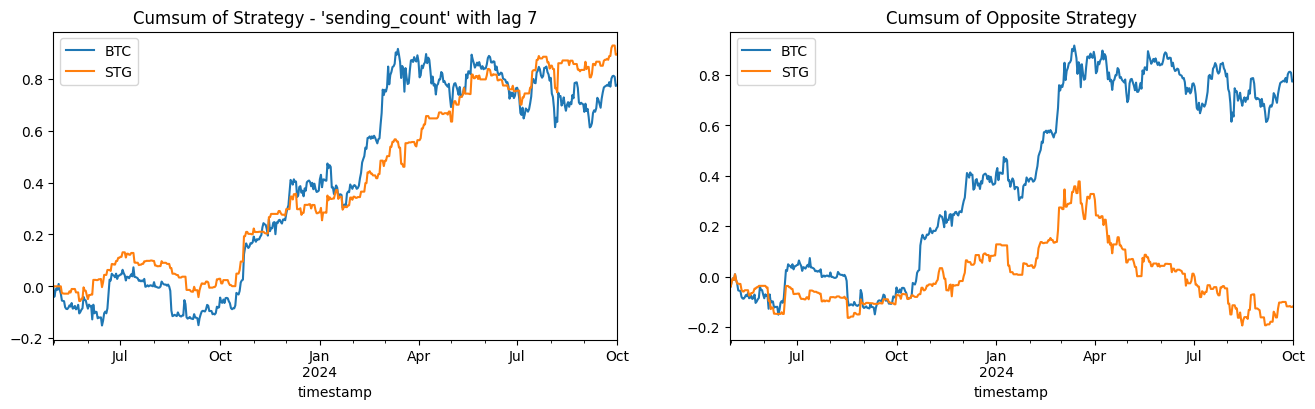

Entire Trading days : 521
Trading days for left: 245                                                                | Trading days for right: 276
Average Return for left: 0.0036                                                           | Average Return for right: -0.0004
Cummulative Sum Return for left: 0.8938                                                   | Cummulative Sum Return for right: -0.1174


In [69]:
test_profitability(test_btc, "sending_count")

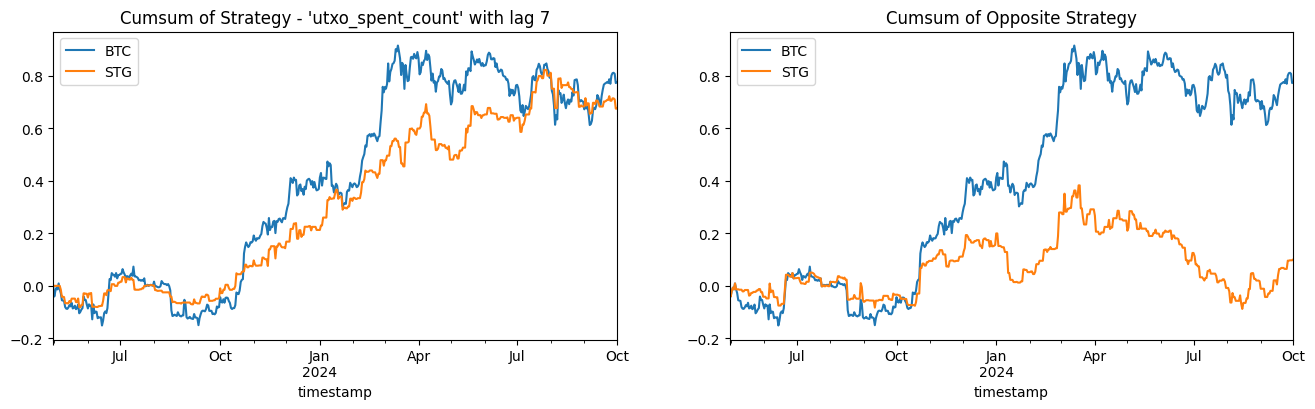

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0026                                                           | Average Return for right: 0.0004
Cummulative Sum Return for left: 0.6756                                                   | Cummulative Sum Return for right: 0.1007


In [70]:
test_profitability(test_btc, "utxo_spent_count")

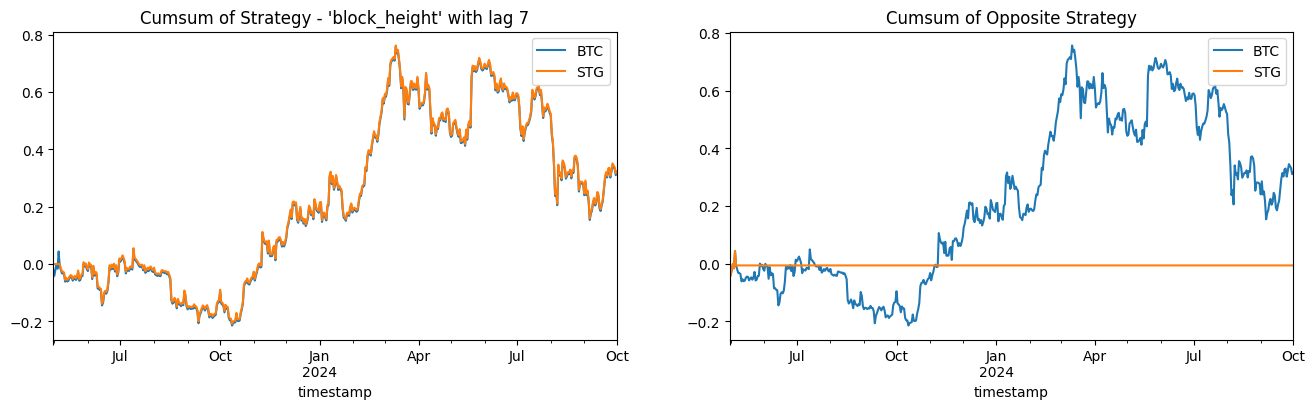

Entire Trading days : 521
Trading days for left: 514                                                                | Trading days for right: 7
Average Return for left: 0.0006                                                           | Average Return for right: -0.0009
Cummulative Sum Return for left: 0.3227                                                   | Cummulative Sum Return for right: -0.0060


In [71]:
test_profitability(test_eth, "block_height")

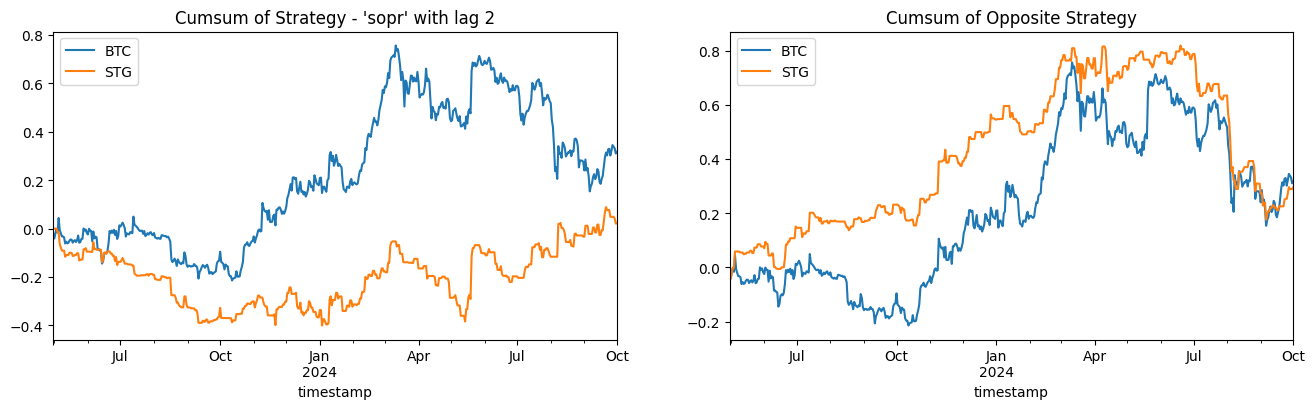

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0001                                                           | Average Return for right: 0.0011
Cummulative Sum Return for left: 0.0210                                                   | Cummulative Sum Return for right: 0.2957


In [72]:
test_profitability(test_eth, "sopr", lag=2)

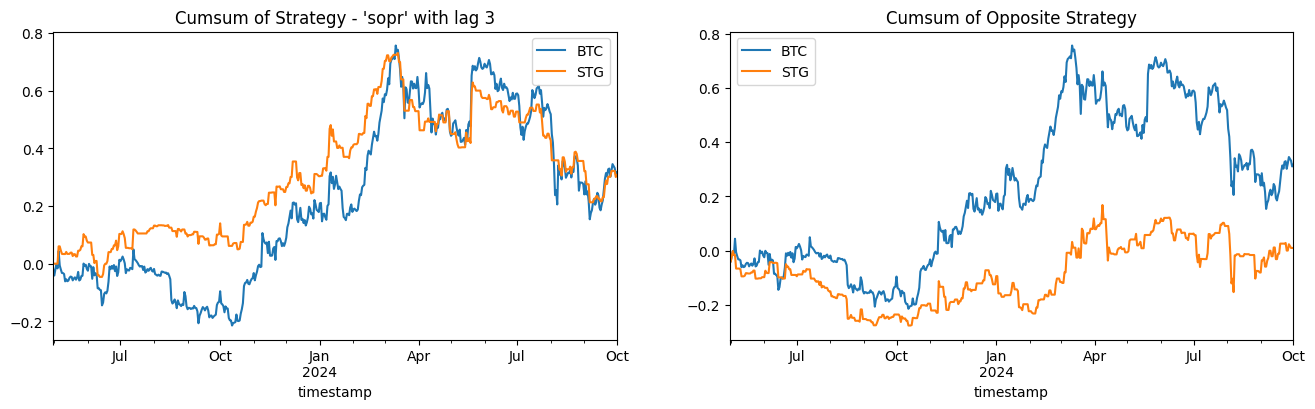

Entire Trading days : 521
Trading days for left: 262                                                                | Trading days for right: 259
Average Return for left: 0.0012                                                           | Average Return for right: 0.0000
Cummulative Sum Return for left: 0.3068                                                   | Cummulative Sum Return for right: 0.0099


In [73]:
test_profitability(test_eth, "sopr", lag=3)

### Using VECM

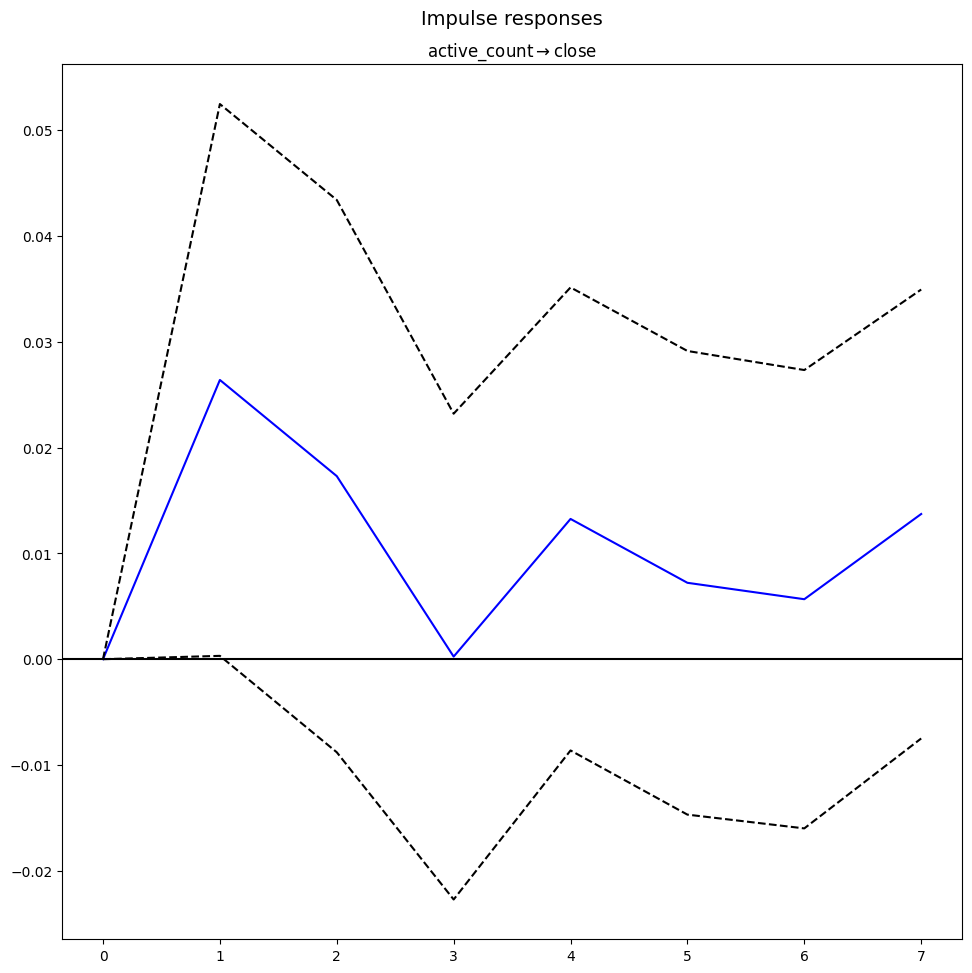

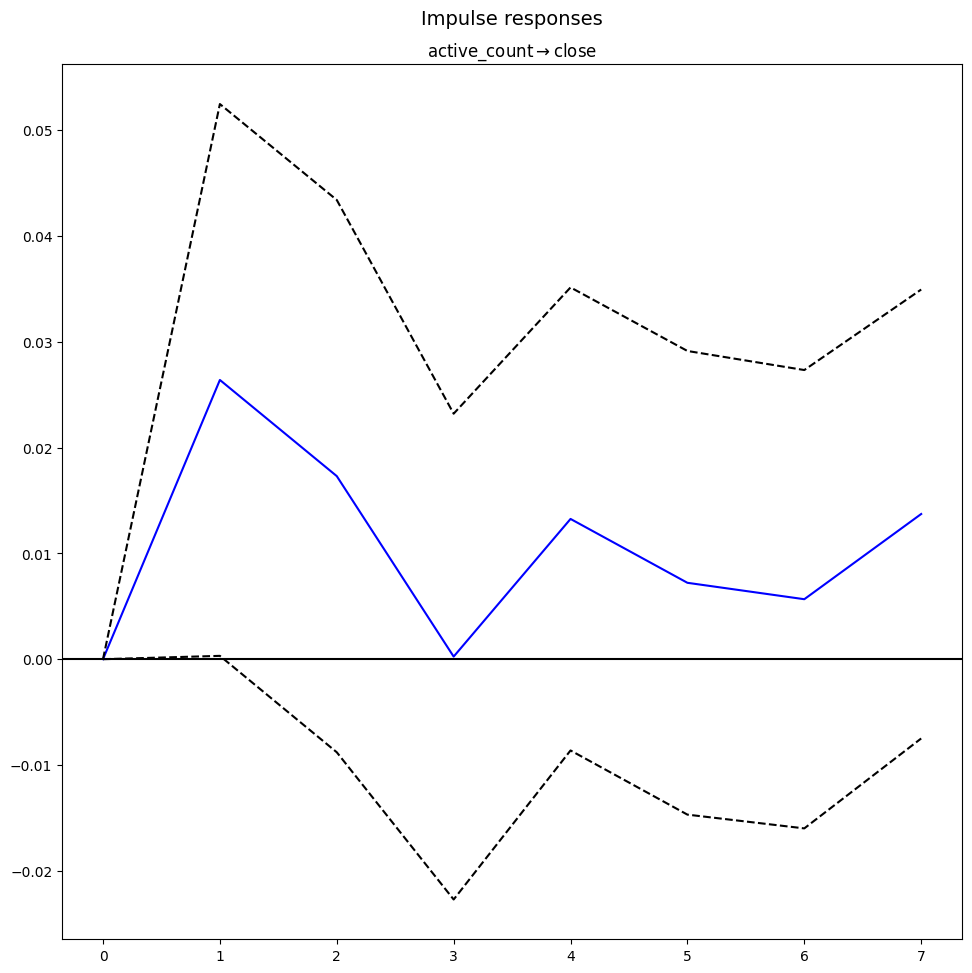

In [39]:
from statsmodels.tsa.api import VAR

coint_result = coint_johansen(train_btc[['close', 'active_count']], det_order=0, k_ar_diff=7)
rank = sum(coint_result.lr1 > coint_result.cvt[:, 1])  # 5% critical value 기준

model = VECM(train_btc[['close', 'active_count']], k_ar_diff=7, coint_rank=rank)
fitted_model = model.fit()
irf = fitted_model.irf(7)  # 10기간 동안의 반응

irf.plot(impulse='active_count', response='close')  # var1이 var2에 미치는 영향

In [34]:
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen
from statsmodels.tsa.api import VAR
import numpy as np

def test_vecm(df, maxlag=10):
    vecm_results = []
    
    for col in df.columns:
        if col == "close":
            continue
        
        # 가장 낮은 AIC 선택
        model = VAR(df[['close', col]])
        lag_order = model.select_order(maxlags=10)
        best_lag = lag_order.aic
        
        # Johansen test to check for cointegration
        coint_result = coint_johansen(df[['close', col]], det_order=0, k_ar_diff=maxlag)
        rank = sum(coint_result.lr1 > coint_result.cvt[:, 1])  # 5% critical value 기준
        
        if rank > 0:  # 공적분 벡터가 존재하는 경우
            # VECM 모델 피팅
            model = VECM(df[['close', col]], k_ar_diff=best_lag, coint_rank=rank)
            fitted_model = model.fit()
        
        if fitted_model is not None:
            # 각 시차별로 유의미한 변수 확인
            print(fitted_model.__dir__())
            for i in range(fitted_model.k_ar_diff):

                if fitted_model.pvalues[i].min() < 0.01:  # 통계적으로 유의미한 경우
                    print(f"{col} : lag {i+1} is statistically significant")
                    print(f"coef: {fitted_model.beta[1][0]}")
                    
            vecm_results.append(fitted_model)
    
    return vecm_results

# 테스트용
space = 30
MAXLAG = 10

print("-"*space + "BTC" + "-"*space)
vecm_btc = test_vecm(train_btc, MAXLAG)
print("-"*space + "ETH" + "-"*space)
vecm_eth = test_vecm(train_eth, MAXLAG)


------------------------------BTC------------------------------
['model', 'y_all', 'exog', 'exog_coint', 'names', 'dates', 'neqs', 'k_ar', 'deterministic', 'seasons', 'first_season', 'coint_rank', 'alpha', 'beta', 'det_coef_coint', 'gamma', 'det_coef', 'const_coint', 'lin_trend_coint', 'exog_coint_coefs', 'const', 'seasonal', 'lin_trend', 'exog_coefs', 'sigma_u', '_delta_y_1_T', '_y_lag1', '_delta_x', 'nobs', '__module__', '__doc__', '__init__', 'llf', '_cov_sigma', 'cov_params_default', 'cov_params_wo_det', 'stderr_params', 'stderr_coint', 'stderr_alpha', 'stderr_beta', 'stderr_det_coef_coint', 'stderr_gamma', 'stderr_det_coef', 'tvalues_alpha', 'tvalues_beta', 'tvalues_det_coef_coint', 'tvalues_gamma', 'tvalues_det_coef', 'pvalues_alpha', 'pvalues_beta', 'pvalues_det_coef_coint', 'pvalues_gamma', 'pvalues_det_coef', '_make_conf_int', 'conf_int_alpha', 'conf_int_beta', 'conf_int_det_coef_coint', 'conf_int_gamma', 'conf_int_det_coef', 'var_rep', 'cov_var_repr', 'ma_rep', '_chol_sigma_u

AttributeError: 'VECMResults' object has no attribute 'k_ar_diff'

In [51]:
import numpy as np
import pandas as pd
from dtaidistance import dtw

# 예제 데이터 생성
np.random.seed(0)
n = 100
time_series_a = np.random.randn(n).cumsum()  # 예시 시계열 A
time_series_b = np.random.randn(n).cumsum()  # 예시 시계열 B

# DataFrame으로 변환
data = pd.DataFrame({'A': time_series_a, 'B': time_series_b})

# DTW 거리 계산
distance, path = dtw.warping_path(data['A'], data['B'])

# 최적의 정렬된 경로 출력
print(f"DTW 거리: {distance}")
print(f"Optimal path: {path}")

# 시차 계산
lag = path[-1][1] - path[-1][0]  # 마지막 포인트에서의 시차
print(f"Lead-lag relationship (lag): {lag}")


ModuleNotFoundError: No module named 'dtaidistance'